# Relatório de Análise Exploratória de Dados — Módulo 2

**Projeto Integrado em Ciência de Dados** · PPGMCS/UNIMONTES
Prof.ª Luciana Balieiro Cosme · Setembro de 2026
Aluno: **Samuel Rodrigues Gonçalves**

**Projeto:** detecção de manipulação da malha de controle em sistema industrial,
com orçamento de alarme. Ficha de escopo entregue no Módulo 1.

Este notebook responde às quatro seções exigidas no enunciado do M2: contexto,
qualidade, distribuições e relações. Toda decisão de pré-processamento aparece com
o número que a motivou e está implementada em `src/preprocess.py`, para ser reusada
nos módulos seguintes.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
sys.path.append(str(Path.cwd().parents[1]))   # raiz do repositório

import numpy as np, pandas as pd
import matplotlib, matplotlib.pyplot as plt

from src import data_loading as dl
from src import preprocess as pp

# paleta única do projeto (usada também no dashboard do M4)
S1, S2, S8 = '#2a78d6', '#eb6834', '#e34948'
SURF, TXT, TXT2, GRID, NEU = '#fcfcfb', '#0b0b0b', '#52514e', '#e3e2df', '#c8ccd1'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': TXT2,
    'text.color': TXT, 'xtick.color': TXT2, 'ytick.color': TXT2,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': .6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'figure.dpi': 110,
})
FIGS = Path.cwd().parents[1] / 'reports' / 'figures'
FIGS.mkdir(parents=True, exist_ok=True)

def cabecalho(fig, titulo, sub):
    fig.text(.005, 1.15, titulo, ha='left', fontsize=12.5, fontweight='bold', color=TXT)
    fig.text(.005, 1.04, sub, ha='left', fontsize=9.5, color=TXT2)

def salvar(fig, nome):
    fig.savefig(FIGS / nome, bbox_inches='tight')

pd.set_option('display.width', 120)
print('pandas', pd.__version__, '| matplotlib', matplotlib.__version__)

pandas 3.0.2 | matplotlib 3.10.9


## 1. Contexto

**Fonte.** HAI Security Dataset, versão 23.05 — National Security Research Institute
(Coreia do Sul). Repositório oficial: <https://github.com/icsdataset/hai>.
Licença Creative Commons BY-SA 4.0, download público e direto, sem cadastro.
**Data de acesso: 19/09/2026** (arquivos reverificados em 26/09/2026).

**O que é.** Telemetria de um testbed industrial composto por turbina a vapor,
sistema de bombeamento hidráulico e simulador *hardware-in-the-loop*, instrumentado
com 86 pontos de processo amostrados a 1 Hz. O instituto executou ataques reais
contra o testbed e rotulou segundo a segundo o período de cada um.

**Período coberto:** 04 a 25/08/2022.
Os CSV brutos não são versionados (ver `.gitignore`); `src/data_loading.py` os baixa
sob demanda a partir do repositório oficial.

In [2]:
normais = dl.carregar_normal()
X, y = dl.carregar_rotulado()

resumo = pd.DataFrame({
    'registros': [len(normais), len(X)],
    'horas': [len(normais)/3600, len(X)/3600],
    'variáveis': [normais.shape[1]-1, X.shape[1]-1],
    'início': [normais.timestamp.min(), X.timestamp.min()],
    'fim': [normais.timestamp.max(), X.timestamp.max()],
}, index=['operação normal (4 arquivos)', 'com ataque (2 arquivos)'])
resumo

,registros,horas,variáveis,início,fim
operação normal (4 arquivos),896400,249.0,86,2022-08-04 18:00:01,2022-08-25 00:00:00
com ataque (2 arquivos),284400,79.0,86,2022-08-12 16:00:01,2022-08-19 16:00:00


In [3]:
print(f'total: {len(normais)+len(X):,} registros  ({(len(normais)+len(X))/3600:.0f} h)')
print(f'segundos rotulados como ataque: {int(y.sum()):,}  ({y.mean()*100:.3f}%)')

# nº de eventos: transições 0->1 na série de rótulos
eventos = int(((y.diff() == 1) | ((y == 1) & (y.index == 0))).sum())
print(f'eventos de ataque distintos: {eventos}')
print('tipos das colunas:', dict(X.drop(columns=["timestamp"]).dtypes.astype(str).value_counts()))

total: 1,180,800 registros  (328 h)
segundos rotulados como ataque: 11,384  (4.003%)
eventos de ataque distintos: 52
tipos das colunas: {'float32': np.int64(86)}


## 2. Qualidade

O checklist do módulo pede tabela de ausentes por coluna com taxa e decisão, e
duplicatas antes/depois. Nos seis arquivos **não há um único valor ausente, nenhuma
linha duplicada e nenhuma lacuna de timestamp** — a série de 1 Hz é contínua.

Isso não significa que o dado esteja limpo. O problema de qualidade aqui é outro, e
de dois tipos: tags sem variância e tags com valores fora da faixa documentada no
manual técnico do dataset.

In [4]:
arquivos = {n: dl.carregar(n) for n in dl.ARQUIVOS_NORMAIS + dl.ARQUIVOS_ATAQUE}

qualidade = pd.DataFrame({
    nome: {
        'linhas': len(df),
        'ausentes': int(df.isna().sum().sum()),
        'duplicatas': int(df.drop(columns=['timestamp']).duplicated().sum()),
        'lacunas de 1s': int((df.timestamp.diff().dt.total_seconds().dropna() != 1).sum()),
    } for nome, df in arquivos.items()
}).T
qualidade

,linhas,ausentes,duplicatas,lacunas de 1s
hai-train1,280800,0,0,0
hai-train2,291600,0,0,0
hai-train3,126000,0,0,0
hai-train4,198000,0,0,0
hai-test1,54000,0,0,0
hai-test2,230400,0,0,0


### 2.1 Tags sem variância

Uma tag constante não carrega informação e atrapalha correlação e normalização.
O cuidado necessário: a lista muda conforme o arquivo observado. Olhando apenas o
`hai-test1` encontram-se 27 tags constantes — mas **10 delas variam em outros
arquivos** e removê-las seria erro. Só é seguro remover o que é constante nos seis.

In [5]:
unicos = pd.DataFrame({n: df.drop(columns=['timestamp']).nunique()
                       for n, df in arquivos.items()})

const_todos = unicos.index[(unicos <= 1).all(axis=1)].tolist()
const_alguns = sorted(set(unicos.index[(unicos <= 1).any(axis=1)]) - set(const_todos))

print(f'constantes nos 6 arquivos  : {len(const_todos)}  -> REMOVER')
print(f'constantes em alguns só    : {len(const_alguns)}  -> MANTER')
print(f'constantes apenas no test1 : {int((unicos["hai-test1"] <= 1).sum())}  '
      '(a lista ingênua, que seria errada)')
print()
print('remover :', const_todos)
print()
print('manter  :', const_alguns)

constantes nos 6 arquivos  : 18  -> REMOVER
constantes em alguns só    : 10  -> MANTER
constantes apenas no test1 : 27  (a lista ingênua, que seria errada)

remover : ['P1_PIT01_HH', 'P1_PP01AD', 'P1_PP01AR', 'P1_PP01BD', 'P1_PP01BR', 'P1_PP02D', 'P1_PP02R', 'P1_SOL01D', 'P1_SOL03D', 'P1_STSP', 'P2_RTR', 'P2_TripEx', 'P2_VTR01', 'P2_VTR02', 'P2_VTR03', 'P2_VTR04', 'P3_LH01', 'P3_LL01']

manter  : ['P1_PCV02D', 'P1_PP04SP', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_Emerg', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_ManualSD', 'P2_OnOff']


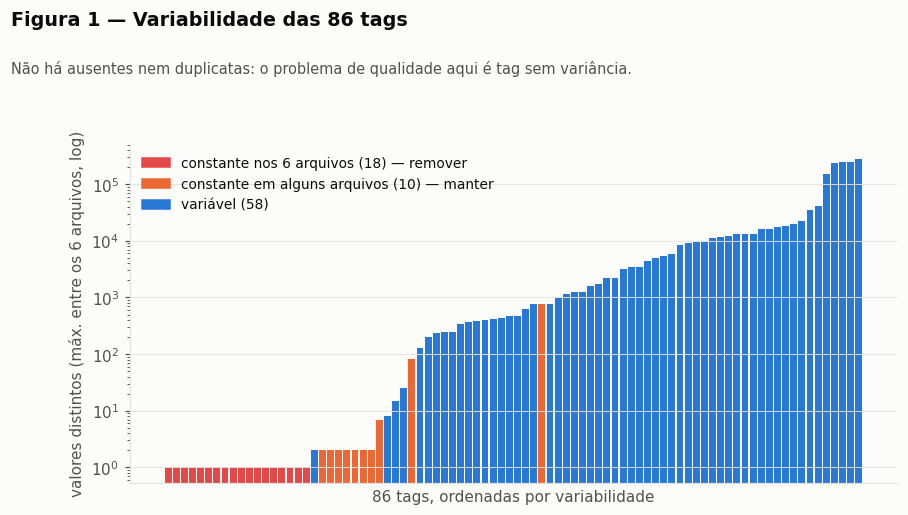

In [6]:
# Figura 1 — variabilidade das 86 tags
tot = unicos.max(axis=1).sort_values()
cores = [S8 if t in set(const_todos) else (S2 if unicos.loc[t].min() <= 1 else S1)
         for t in tot.index]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(range(len(tot)), tot.values.clip(1), color=cores, width=.85)
ax.set_yscale('log'); ax.set_xticks([])
ax.set_ylabel('valores distintos (máx. entre os 6 arquivos, log)')
ax.set_xlabel('86 tags, ordenadas por variabilidade')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=S8, label=f'constante nos 6 arquivos ({len(const_todos)}) — remover'),
                   Patch(color=S2, label=f'constante em alguns arquivos ({len(const_alguns)}) — manter'),
                   Patch(color=S1, label=f'variável ({86-len(const_todos)-len(const_alguns)})')],
          loc='upper left', fontsize=9)
cabecalho(fig, 'Figura 1 — Variabilidade das 86 tags',
          'Não há ausentes nem duplicatas: o problema de qualidade aqui é tag sem variância.')
salvar(fig, 'f4_qualidade.png'); plt.show()

**Decisão D1.** Remover as 18 tags constantes nos seis arquivos; manter as 10 que são
constantes apenas em parte deles. Implementado em `pp.remover_constantes()`.
Sobram 68 variáveis.

### 2.2 Valores fora da faixa documentada

O manual técnico do dataset (`hai_dataset_technical_details.pdf`, no repositório oficial)
publica a faixa esperada de cada tag. Comparando com o observado aparecem 15 divergências
— o equivalente, aqui, ao `SpO2 = 0` que o material da disciplina usa como exemplo de
valor impossível.

In [7]:
faixas = {  # min, max, unidade — transcritos do manual técnico
    'P3_LCV01D': (0, 27648, '-'), 'P3_LCP01D': (0, 27648, '-'),
    'P3_LIT01': (0, 90, '%'), 'P1_FT02': (0, 2500, 'mmH2O'),
    'P1_PIT01': (0, 10, 'bar'), 'P2_VT01': (11, 12, 'rad/s'),
    'P1_PIT01_HH': (0, 10, 'bar'), 'P1_SOL01D': (0, 1, 'bool'),
    'P1_SOL03D': (0, 1, 'bool'), 'P2_VTR01': (-10, 10, 'um'),
}
obs_min = pd.concat([df.drop(columns=['timestamp']).min() for df in arquivos.values()], axis=1).min(axis=1)
obs_max = pd.concat([df.drop(columns=['timestamp']).max() for df in arquivos.values()], axis=1).max(axis=1)

linhas = []
for tag, (mn, mx, un) in faixas.items():
    linhas.append({'tag': tag, 'min_doc': mn, 'max_doc': mx, 'unidade': un,
                   'min_obs': round(float(obs_min[tag]), 4),
                   'max_obs': round(float(obs_max[tag]), 4),
                   'fora': bool(obs_min[tag] < mn or obs_max[tag] > mx)})
pd.DataFrame(linhas).set_index('tag')

,min_doc,max_doc,unidade,min_obs,max_obs,fora
tag,,,,,,
P3_LCV01D,0,27648,-,-176.0000,19408.0000,True
P3_LCP01D,0,27648,-,-16.0000,13824.0000,True
P3_LIT01,0,90,%,7969.0000,19757.0000,True
P1_FT02,0,2500,mmH2O,1.1825,2513.9236,True
P1_PIT01,0,10,bar,-0.0060,2.0494,True
P2_VT01,11,12,rad/s,0.0000,13.1586,True
P1_PIT01_HH,0,10,bar,524320.0000,524320.0000,True
P1_SOL01D,0,1,bool,524320.0000,524320.0000,True
P1_SOL03D,0,1,bool,524320.0000,524320.0000,True


**Decisão D2 — caso a caso, como o domínio manda.**

| Tag | Situação | Decisão |
|---|---|---|
| `P3_LCV01D`, `P3_LCP01D` | comando de válvula **negativo** (faixa 0–27648) | clipar em zero **e criar flag** marcando a ocorrência |
| `P3_LIT01` | documentada em 0–90%, observada entre 7.969 e 19.757 | escala crua, não convertida — documentar e manter |
| `P1_FT02` | excede o máximo em 0,6% | ruído de sensor — manter |
| `P1_PIT01` | mínimo −0,006 bar | ruído em torno de zero — manter |
| `P2_VT01` | abaixo da faixa nominal | máquina parada, sinal real — manter |
| `P1_PIT01_HH`, `P1_SOL01D/03D`, `P2_VTR0x` | travadas em valor fora de faixa | já saem por D1 (variância zero) |

Outlier que é sinal não se remove. Implementado em `pp.tratar_valores_impossiveis()`.

Uma consequência que corrige a ficha do M1: `P1_PIT01_HH` é descrita no manual como
*"Highest outlet pressure of the heat-exchanger"*, faixa 0–10 bar, e está travada em
524320 nas 328 horas. **Não serve** como alarme convencional de referência, como eu
havia suposto. A comparação com alarme por limite fixo terá de usar um limiar definido
por mim sobre `P1_PIT01`, declarado como tal no M3.

## 3. Distribuições

### 3.1 A variável-alvo

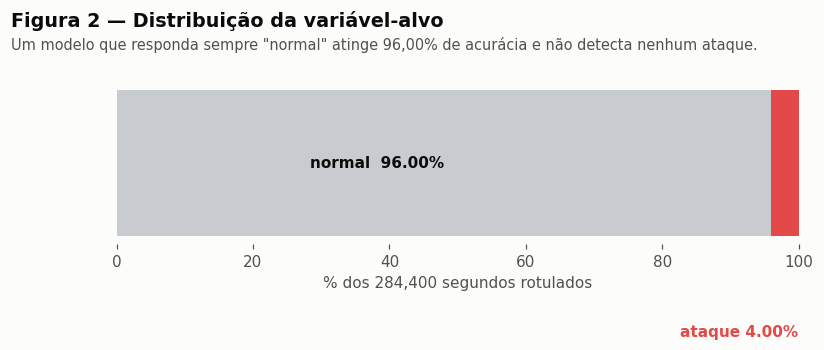

In [8]:
# Figura 2 — distribuição do alvo
p = y.mean() * 100
fig, ax = plt.subplots(figsize=(8, 1.9))
ax.barh([0], [100-p], color=NEU, height=.5)
ax.barh([0], [p], left=[100-p], color=S8, height=.5)
ax.set_xlim(0, 100); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel(f'% dos {len(y):,} segundos rotulados')
ax.text(48, 0, f'normal  {100-p:.2f}%', ha='right', va='center', color=TXT, fontweight='bold')
ax.text(100, -.55, f'ataque {p:.2f}%', ha='right', va='top', color=S8, fontweight='bold')
for s in ['left', 'bottom']: ax.spines[s].set_visible(False)
cabecalho(fig, 'Figura 2 — Distribuição da variável-alvo',
          'Um modelo que responda sempre "normal" atinge 96,00% de acurácia e não detecta nenhum ataque.')
salvar(fig, 'f2_alvo.png'); plt.show()

**Taxa de desbalanceamento: 1 para 24.** A consequência é direta e já estava antecipada
na ficha do M1: **a acurácia é inutilizável** como métrica. A métrica primária do projeto é
cobertura de eventos sob orçamento de alarme (proporção dos 52 ataques detectados com no
máximo 1 alarme falso por hora), com latência mediana de detecção como métrica de apoio e
PR-AUC como complementar.

Sobre reamostragem: **SMOTE não será usado**. Ele interpola entre amostras vizinhas, e em
janelas de série temporal as vizinhas compartilham segundos — a amostra sintética carregaria
informação da janela ao lado, o que é vazamento disfarçado de balanceamento.
A opção adotada é `class_weight='balanced'`, que o próprio material aponta como alternativa
mais simples e que não inventa dado.

### 3.2 Duração dos eventos

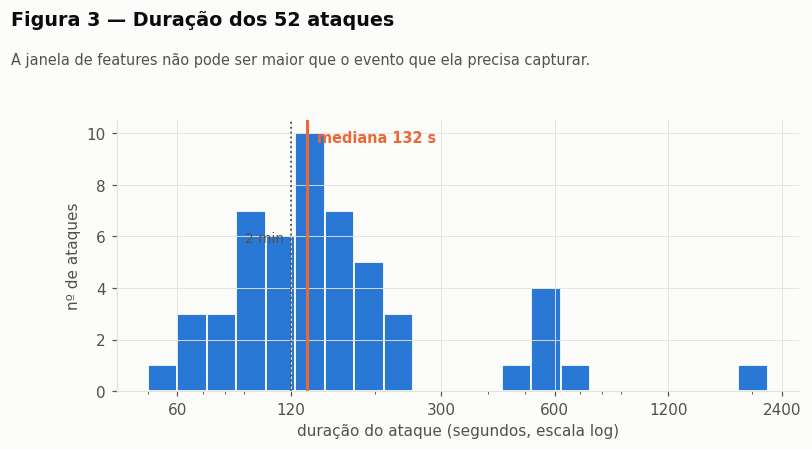

mín 56 s · p25 97 s · mediana 132 s · p75 197 s · máx 2052 s
ataques com menos de 2 minutos: 17 de 52


In [9]:
# Figura 3 — duração dos 52 ataques
ch = (y.diff() != 0).cumsum()
segs = [(g.index[0], g.index[-1]) for _, g in y.groupby(ch) if g.iloc[0] == 1]
dur = np.array([b - a + 1 for a, b in segs])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(dur, bins=np.logspace(np.log10(50), np.log10(2200), 22), color=S1,
        edgecolor=SURF, lw=1.2)
ax.set_xscale('log'); ax.set_xlabel('duração do ataque (segundos, escala log)')
ax.set_ylabel('nº de ataques')
ax.axvline(np.median(dur), color=S2, lw=2)
ax.text(np.median(dur)*1.06, ax.get_ylim()[1]*.92, f'mediana {np.median(dur):.0f} s',
        color=S2, fontweight='bold', fontsize=9.5)
ax.axvline(120, color=TXT2, lw=1.2, ls=':')
ax.text(118, ax.get_ylim()[1]*.55, '2 min ', color=TXT2, fontsize=9, ha='right')
ax.set_xticks([60, 120, 300, 600, 1200, 2400])
ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f'{v:.0f}'))
cabecalho(fig, 'Figura 3 — Duração dos 52 ataques',
          'A janela de features não pode ser maior que o evento que ela precisa capturar.')
salvar(fig, 'f3_duracao.png'); plt.show()

print(f'mín {dur.min()} s · p25 {np.percentile(dur,25):.0f} s · mediana {np.median(dur):.0f} s · '
      f'p75 {np.percentile(dur,75):.0f} s · máx {dur.max()} s')
print(f'ataques com menos de 2 minutos: {(dur < 120).sum()} de {len(dur)}')

**Consequência para o M3.** 17 dos 52 ataques duram menos de 2 minutos e o mais curto
tem 56 s. Uma janela de 5 minutos diluiria o evento no ruído; uma de 30 s pode não capturar
a dinâmica. O tamanho da janela vira **experimento rastreado**, varrendo de 30 a 120 s, e não
escolha arbitrária. `pp.janelas()` já recebe o tamanho como parâmetro.

### 3.3 Um evento, de perto

Antes das distribuições agregadas, vale ver o que é um ataque nesta série. O A101 manipula
o setpoint do controlador de pressão e restaura em rampa, escondendo a mudança na IHM.

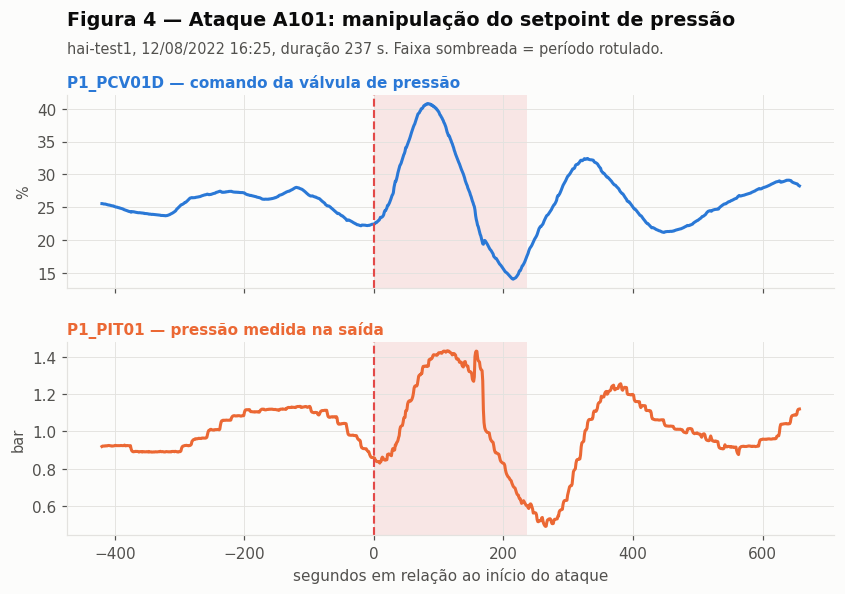

In [10]:
# Figura 4 — o evento A101
t1 = arquivos['hai-test1']; y1 = dl.carregar('label-test1')['label']
ch1 = (y1.diff() != 0).cumsum()
ev1 = [(g.index[0], g.index[-1]) for _, g in y1.groupby(ch1) if g.iloc[0] == 1]
a, b = ev1[0]; lo, hi = max(0, a-420), min(len(t1)-1, b+420)
x = np.arange(lo, hi+1) - a

fig, axes = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True,
                         gridspec_kw={'hspace': .28})
for ax, tag, col, lab, un in [(axes[0], 'P1_PCV01D', S1, 'P1_PCV01D — comando da válvula de pressão', '%'),
                              (axes[1], 'P1_PIT01', S2, 'P1_PIT01 — pressão medida na saída', 'bar')]:
    ax.plot(x, t1[tag].values[lo:hi+1], color=col, lw=2)
    ax.axvspan(0, b-a, color=S8, alpha=.12, lw=0)
    ax.axvline(0, color=S8, lw=1.4, ls='--')
    ax.set_ylabel(un, fontsize=9.5)
    ax.text(0, 1.02, lab, transform=ax.transAxes, color=col, fontsize=10,
            fontweight='bold', va='bottom')
axes[1].set_xlabel('segundos em relação ao início do ataque')
axes[0].text(0, 1.34, 'Figura 4 — Ataque A101: manipulação do setpoint de pressão',
             transform=axes[0].transAxes, color=TXT, fontsize=12.5, fontweight='bold', va='bottom')
axes[0].text(0, 1.20, 'hai-test1, 12/08/2022 16:25, duração 237 s. Faixa sombreada = período rotulado.',
             transform=axes[0].transAxes, color=TXT2, fontsize=9.5, va='bottom')
salvar(fig, 'f1_evento_a101.png'); plt.show()

O comando sobe e volta dentro da faixa operacional normal — em nenhum momento a
pressão sai de faixa. É por isso que alarme por limite fixo não pega este ataque: ele
não foi feito para adversário, foi feito para falha de equipamento.

### 3.4 Histogramas das features principais

variáveis após D1: 68


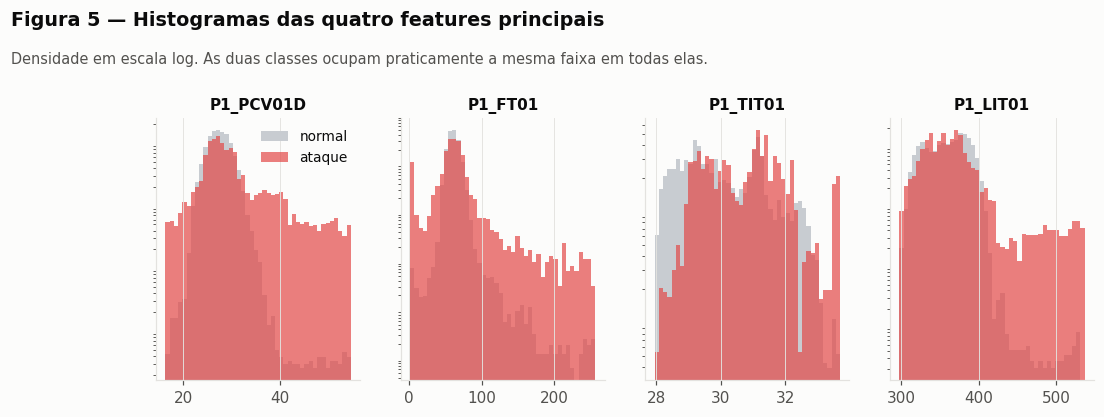

In [11]:
Xv = pp.remover_constantes(X.drop(columns=['timestamp']))
print('variáveis após D1:', Xv.shape[1])

# Figura 5 — histogramas normal x ataque
tags = ['P1_PCV01D', 'P1_FT01', 'P1_TIT01', 'P1_LIT01']
fig, axes = plt.subplots(1, 4, figsize=(11, 3.1))
for ax, tg in zip(axes, tags):
    n, a_ = Xv.loc[y == 0, tg].values, Xv.loc[y == 1, tg].values
    lo_, hi_ = np.percentile(np.r_[n, a_], .2), np.percentile(np.r_[n, a_], 99.8)
    bins = np.linspace(lo_, hi_, 45)
    ax.hist(n, bins=bins, density=True, color=NEU, label='normal')
    ax.hist(a_, bins=bins, density=True, color=S8, alpha=.7, label='ataque')
    ax.set_yscale('log'); ax.set_yticks([])
    ax.text(.5, 1.03, tg, transform=ax.transAxes, ha='center', fontsize=10,
            fontweight='bold', color=TXT)
axes[0].legend(fontsize=9, loc='upper right')
cabecalho(fig, 'Figura 5 — Histogramas das quatro features principais',
          'Densidade em escala log. As duas classes ocupam praticamente a mesma faixa em todas elas.')
salvar(fig, 'f9_histogramas.png'); plt.show()

As distribuições marginais se sobrepõem quase inteiramente. **Nenhuma das quatro separa
as classes sozinha** — primeira evidência de que o sinal é multivariado, hipótese registrada
na ficha do M1.

Assimetria: 18 das 68 variáveis têm |skew| > 3, as de vibração de P2 chegando a −80.
Isso é o argumento para `RobustScaler` em vez de `StandardScaler` no ramo de modelos
sensíveis a escala.

In [12]:
sk = Xv.skew().sort_values(key=abs, ascending=False)
print(f'variáveis com |assimetria| > 3: {int((sk.abs() > 3).sum())} de {Xv.shape[1]}')
sk.head(6).round(2)

variáveis com |assimetria| > 3: 18 de 68


P2_VIBTR04   -79.919998
P2_VIBTR03   -61.509998
P2_Emerg      54.980000
P2_OnOff     -49.700001
P2_VT01      -46.500000
P2_VIBTR01   -37.939999
dtype: float32

## 4. Relações

### 4.1 Correlação com o alvo

In [13]:
cy = Xv.corrwith(y).sort_values(key=abs, ascending=False)
print('TOP 5 correlações com o alvo:'); print(cy.head(5).round(4).to_string())
print(f'\nmaior |r| com o alvo em todo o conjunto: {cy.abs().max():.4f}')

TOP 5 correlações com o alvo:
P1_PCV02D    0.1993
P1_PCV02Z    0.1954
P1_PCV01D    0.1800
P1_PCV01Z    0.1788
P1_FT01      0.1267

maior |r| com o alvo em todo o conjunto: 0.1993


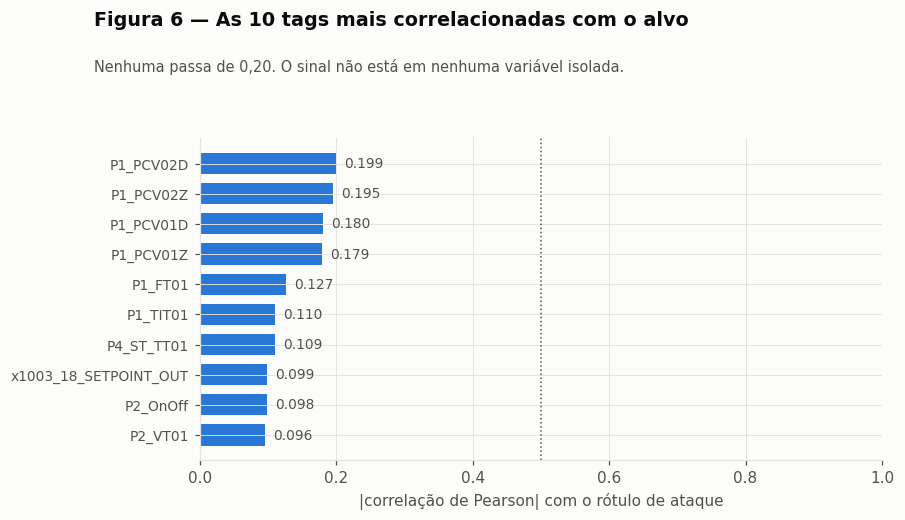

In [14]:
# Figura 6 — correlações com o alvo
top = cy.head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(range(len(top)), top.abs().values, color=S1, height=.7)
ax.set_yticks(range(len(top))); ax.set_yticklabels(top.index, fontsize=9)
ax.set_xlim(0, 1); ax.set_xlabel('|correlação de Pearson| com o rótulo de ataque')
ax.axvline(.5, color=TXT2, ls=':', lw=1)
for i, v in enumerate(top.abs().values):
    ax.text(v + .012, i, f'{v:.3f}', va='center', fontsize=9, color=TXT2)
cabecalho(fig, 'Figura 6 — As 10 tags mais correlacionadas com o alvo',
          'Nenhuma passa de 0,20. O sinal não está em nenhuma variável isolada.')
salvar(fig, 'f5_corr_alvo.png'); plt.show()

Esse é o resultado mais importante da seção. A maior correlação linear de qualquer tag
com o rótulo é **0,199** — praticamente nula. Lido de forma ingênua, sugeriria que o problema
não tem solução. Lido corretamente, confirma a hipótese do M1: a assinatura do ataque é
**multivariada e de janela**, não pontual e univariada. Um detector construído sobre uma
única tag está condenado, e é exatamente o que o baseline do M1 mostrou (1 de 14 eventos).

### 4.2 A feature que a correlação de Pearson não enxerga

`P1_PCV02D` é a tag de maior correlação com o alvo e, ao mesmo tempo, fica parada no
mesmo valor quase o tempo todo. Vale investigar **onde** ela se move.

P1_PCV02D: valor de repouso = 12, presente em 99.65% do tempo
sai do repouso em 0.073% dos segundos normais e 6.887% dos segundos sob ataque  ->  94x


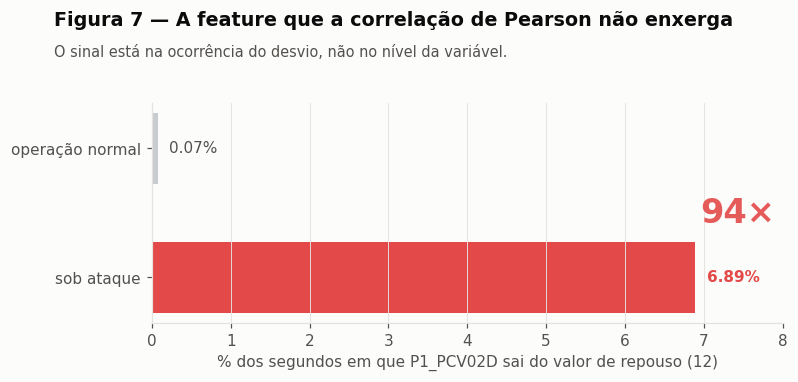

In [15]:
tag = 'P1_PCV02D'; repouso = Xv[tag].mode().iloc[0]
rn = ((Xv[tag] != repouso) & (y == 0)).sum() / (y == 0).sum() * 100
ra = ((Xv[tag] != repouso) & (y == 1)).sum() / (y == 1).sum() * 100
print(f'{tag}: valor de repouso = {repouso:g}, presente em {(Xv[tag]==repouso).mean()*100:.2f}% do tempo')
print(f'sai do repouso em {rn:.3f}% dos segundos normais e {ra:.3f}% dos segundos sob ataque  ->  {ra/rn:.0f}x')

fig, ax = plt.subplots(figsize=(7.4, 2.6))
ax.barh([1, 0], [rn, ra], color=[NEU, S8], height=.55)
ax.set_yticks([1, 0]); ax.set_yticklabels(['operação normal', 'sob ataque'], fontsize=10)
ax.set_xlabel(f'% dos segundos em que {tag} sai do valor de repouso ({repouso:g})')
ax.set_xlim(0, 8); ax.grid(axis='y', visible=False)
ax.text(rn + .15, 1, f'{rn:.2f}%', va='center', fontsize=10, color=TXT2)
ax.text(ra + .15, 0, f'{ra:.2f}%', va='center', fontsize=10, fontweight='bold', color=S8)
ax.text(7.9, .5, f'{ra/rn:.0f}×', ha='right', va='center', fontsize=22,
        fontweight='bold', color=S8, alpha=.9)
cabecalho(fig, 'Figura 7 — A feature que a correlação de Pearson não enxerga',
          'O sinal está na ocorrência do desvio, não no nível da variável.')
salvar(fig, 'f11_desvio_repouso.png'); plt.show()

**Decisão D3 — engenharia de features.** A relação não é linear no nível da variável,
é na **ocorrência do desvio** — por isso Pearson subestima. Criar a feature binária
`P1_PCV02D_fora_repouso`, que vale 1 quando a tag sai do valor de repouso.
Implementado em `pp.taxa_desvio_repouso()`.

### 4.3 Matriz de correlação e pares críticos

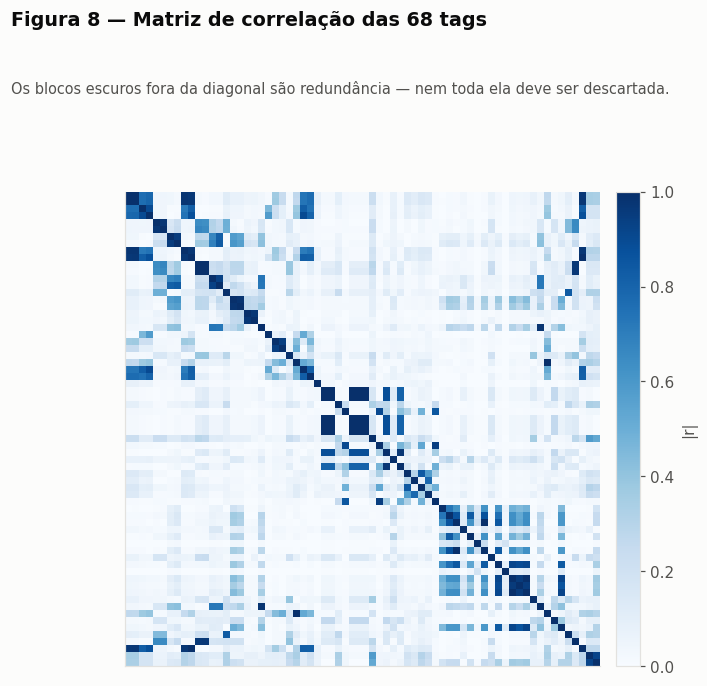

pares com |r| > 0,95: 34


,tag A,tag B,|r|
0,P2_ATSW_Lamp,P2_AutoGO,1.0000
1,P2_ATSW_Lamp,P2_MASW,1.0000
2,P2_ATSW_Lamp,P2_MASW_Lamp,1.0000
3,P2_ATSW_Lamp,P2_ManualGO,1.0000
4,P2_AutoGO,P2_MASW,1.0000
5,P2_AutoGO,P2_MASW_Lamp,1.0000
6,P2_AutoGO,P2_ManualGO,1.0000
7,P2_MASW,P2_MASW_Lamp,1.0000
8,P2_MASW,P2_ManualGO,1.0000
9,P2_MASW_Lamp,P2_ManualGO,1.0000


In [16]:
C = Xv.corr().abs()
fig, ax = plt.subplots(figsize=(6.4, 5.6))
im = ax.imshow(C.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=.046, pad=.03)
cb.set_label('|r|', color=TXT2); cb.outline.set_edgecolor(GRID)
cabecalho(fig, 'Figura 8 — Matriz de correlação das 68 tags',
          'Os blocos escuros fora da diagonal são redundância — nem toda ela deve ser descartada.')
salvar(fig, 'f6_matriz.png'); plt.show()

M = C.to_numpy(copy=True); cols = list(C.columns); np.fill_diagonal(M, 0)
pares = sorted([(cols[i], cols[j], M[i, j]) for i in range(len(cols))
                for j in range(i+1, len(cols)) if M[i, j] > .95], key=lambda t: -t[2])
print(f'pares com |r| > 0,95: {len(pares)}')
pd.DataFrame(pares[:12], columns=['tag A', 'tag B', '|r|']).round(4)

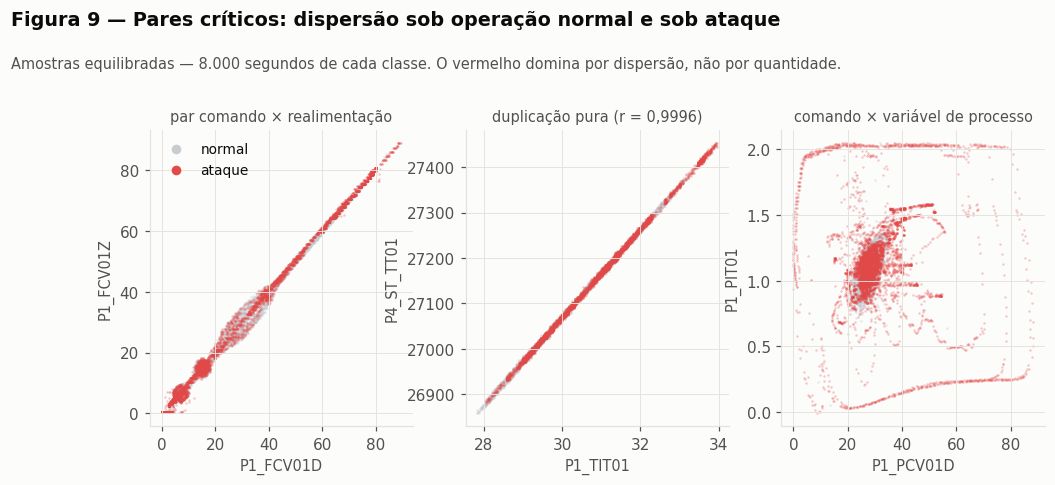

In [17]:
# Figura 9 — scatter dos pares críticos
pares_fig = [('P1_FCV01D', 'P1_FCV01Z', 'par comando × realimentação'),
             ('P1_TIT01', 'P4_ST_TT01', 'duplicação pura (r = 0,9996)'),
             ('P1_PCV01D', 'P1_PIT01', 'comando × variável de processo')]
idx_n, idx_a = np.where(y.values == 0)[0], np.where(y.values == 1)[0]
rng = np.random.default_rng(42); NS = 8000
sn, sa = rng.choice(idx_n, NS, replace=False), rng.choice(idx_a, NS, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.5))
for ax, (xa, ya, sub) in zip(axes, pares_fig):
    ax.scatter(Xv[xa].values[sn], Xv[ya].values[sn], s=2.5, color=NEU, alpha=.45, lw=0, label='normal')
    ax.scatter(Xv[xa].values[sa], Xv[ya].values[sa], s=2.5, color=S8, alpha=.30, lw=0, label='ataque')
    ax.set_xlabel(xa, fontsize=9.5); ax.set_ylabel(ya, fontsize=9.5)
    ax.text(.5, 1.03, sub, transform=ax.transAxes, ha='center', fontsize=9.5, color=TXT2)
lg = axes[0].legend(fontsize=9, markerscale=4, loc='upper left')
for h in lg.legend_handles: h.set_alpha(1)
cabecalho(fig, 'Figura 9 — Pares críticos: dispersão sob operação normal e sob ataque',
          'Amostras equilibradas — 8.000 segundos de cada classe. O vermelho domina por dispersão, não por quantidade.')
salvar(fig, 'f10_scatter_pares.png'); plt.show()

Três leituras, uma por painel.

**Par comando × realimentação.** Em operação normal a válvula segue o comando: os pontos
formam uma reta estreita. Sob ataque a nuvem se estica muito além da faixa normal — o
comando é levado a valores que a operação legítima nunca usa.

**Duplicação pura.** `P1_TIT01` e `P4_ST_TT01` são a mesma informação medida duas vezes.
Uma das duas é descartável sem perda.

**Comando × variável de processo.** Sob ataque o envelope operacional se abre bem além da
nuvem normal, *mesmo com as distribuições marginais se sobrepondo* (Figura 5). É a evidência
visual mais direta de que o sinal só aparece na relação entre variáveis.

**Decisão D4 — três tratamentos para os 34 pares, não um.**

| Situação | Tratamento | Por quê |
|---|---|---|
| duplicação pura | remove a menos interpretável | regra do módulo, aplicada direto |
| bloco de 6 tags de P2 com r = 1,000 | colapsa em uma | é uma variável repetida seis vezes |
| pares comando/realimentação | **substitui o par pela diferença** | descartar um lado apagaria o resíduo que carrega o sinal |

O terceiro caso é um **desvio consciente** da regra "remova a menos interpretável", e fica
registrado como tal. A regra existe para eliminar redundância que prejudica modelos lineares;
substituir o par pela diferença cumpre esse objetivo **e** preserva a informação que a
redundância esconde. Implementado em `pp.tratar_redundancia()`.

## 5. Pré-processamento consolidado

Todas as decisões acima estão em `src/preprocess.py` e são chamadas por uma única função,
`pp.preparar()`, reutilizada nos notebooks do M3 e no app do M4.

In [18]:
Xp = pp.preparar(X)
print(f'antes : {X.shape[1]-1} variáveis')
print(f'depois: {Xp.shape[1]} variáveis')
print()
print('criadas:', [c for c in Xp.columns if c.endswith(('_residuo', '_impossivel', '_fora_repouso'))])
Xp.head(3)

antes : 86 variáveis
depois: 64 variáveis

criadas: ['P3_LCV01D_impossivel', 'P3_LCP01D_impossivel', 'P1_PCV02D_fora_repouso', 'P1_FCV01_residuo', 'P1_FCV02_residuo', 'P1_FCV03_residuo', 'P1_LCV01_residuo', 'P1_PCV01_residuo', 'P1_PCV02_residuo']


,P1_FCV01D,P1_FCV02D,P1_FCV03D,P1_FT01,P1_FT01Z,P1_FT02,P1_FT02Z,P1_FT03,P1_FT03Z,P1_LCV01D,...,x1003_24_SUM_OUT,P3_LCV01D_impossivel,P3_LCP01D_impossivel,P1_PCV02D_fora_repouso,P1_FCV01_residuo,P1_FCV02_residuo,P1_FCV03_residuo,P1_LCV01_residuo,P1_PCV01_residuo,P1_PCV02_residuo
0,60.993160,15.0,50.534321,64.697273,336.857086,2387.847656,3116.427979,237.503006,980.941772,19.113131,...,30.253811,0,0,0,0.498161,2.55493,-1.461529,0.511141,-0.642670,0.31024
1,60.937069,15.0,50.505589,63.934311,332.884613,2375.259521,3108.170166,237.693771,980.506836,19.164730,...,30.263350,0,0,0,0.434448,2.55493,-1.497890,0.562740,-0.642302,0.30261
2,61.089630,15.0,50.528191,65.078743,332.884613,2379.074219,3110.672607,237.884476,980.941772,19.124029,...,30.273270,0,0,0,0.587009,2.55493,-1.475288,0.522039,-0.575272,0.31024


### Normalização — dois ramos, não um

O material da disciplina é explícito: `StandardScaler` para modelos que assumem normalidade
ou usam distância, `RobustScaler` quando há outliers relevantes, e **árvores e boosting não
precisam de normalização**. Como o M3 vai comparar regressão logística com gradient boosting,
a escolha é condicional ao modelo:

- **ramo logístico** → `RobustScaler` (mediana e IQR), por causa das 18 variáveis com |skew| > 3;
- **ramo árvore/boosting** → sem normalização.

E a regra que vale para os dois: o `fit` vê **apenas** o trecho de treino. Em série temporal
isso significa o trecho cronologicamente **anterior** ao corte — ajustar no conjunto inteiro
vazaria estatística do futuro para o passado.

In [19]:
# fronteira cronológica: test1 inteiro + 60% do test2 para treino
n_test1 = len(arquivos['hai-test1'])
corte = n_test1 + int(.6 * (len(X) - n_test1))
print(f'treino: segundos 0 a {corte:,}   ({corte/3600:.1f} h)')
print(f'teste : segundos {corte:,} a {len(X):,}   ({(len(X)-corte)/3600:.1f} h)')

scaler = pp.ajustar_scaler(Xp.iloc[:corte])          # fit SÓ no treino
Xs = pp.aplicar_scaler(scaler, Xp)
print(f'\nmediana no treino após escalar: {Xs.iloc[:corte].median().abs().max():.3f} (esperado ~0)')

treino: segundos 0 a 192,240   (53.4 h)
teste : segundos 192,240 a 284,400   (25.6 h)



mediana no treino após escalar: 0.000 (esperado ~0)


In [20]:
# janelas: descarta as que cruzam a fronteira, para não misturar treino e teste
F, yf = pp.janelas(Xp, y, tamanho=60, passo=30, corte=corte)
print(f'janelas de 60 s com passo 30 s: {len(F):,}')
print(f'features por janela: {F.shape[1]-1}  (média, desvio e delta de cada variável)')
print(f'janelas rotuladas como ataque: {int(yf.sum()):,}  ({yf.mean()*100:.2f}%)')

janelas de 60 s com passo 30 s: 9,478
features por janela: 192  (média, desvio e delta de cada variável)
janelas rotuladas como ataque: 467  (4.93%)


## 6. Síntese

**Qualidade.** Zero ausentes, zero duplicatas, zero lacunas de timestamp nos seis arquivos.
Os problemas reais são 18 tags sem variância e 15 tags fora da faixa documentada — dessas,
apenas duas exigiram intervenção (comando de válvula negativo, clipado e sinalizado).

**Distribuições.** Alvo em 4,00%, 1 para 24. Acurácia descartada como métrica. SMOTE
descartado por risco de vazamento em série temporal; `class_weight='balanced'` no lugar.
17 dos 52 ataques duram menos de 2 minutos, o que limita o tamanho da janela.

**Relações.** Maior correlação de qualquer tag com o alvo: 0,199. Nenhuma variável isolada
resolve o problema, o que confirma a hipótese do M1 e justifica a abordagem multivariada.
34 pares redundantes, tratados em três categorias distintas em vez de uma regra única.

**Achado próprio do módulo.** `P1_PCV02D` sai do valor de repouso 94 vezes mais
frequentemente sob ataque do que em operação normal (6,89% contra 0,07%) — uma feature que
a correlação linear não enxerga porque o sinal está na ocorrência do desvio, não no nível.

### Próximos passos (M3)

1. Varrer o tamanho da janela de 30 a 120 s como experimento rastreado, e não como escolha fixa.
2. Estabelecer os baselines: alarme por limite fixo, resíduo comando/realimentação
   (1 de 14 eventos, já medido no M1) e Isolation Forest treinado só nas 249 h normais.
3. Comparar regressão logística regularizada e gradient boosting, com `class_weight='balanced'`,
   avaliando por cobertura de eventos sob orçamento de 1 alarme falso por hora.

---

### Declaração de uso de Inteligência Artificial

Declaro que utilizei a ferramenta de Inteligência Artificial **Claude (Anthropic)**, em setembro 
de 2026, como apoio na elaboração deste trabalho: revisão das rotinas
de exploração sobre os arquivos do dataset e revisão da redação. Afirmo
que li, revisei e adaptei todo o conteúdo, mantendo responsabilidade integral sobre o material
apresentado. Não foram produzidos por IA: a escolha do domínio e do problema, a definição do
recorte, a elaboração inicial dos códigos e as decisões de pré-processamento deste módulo. 
O diário de prompts está em `prompts_log.md`, na raiz do repositório.